# GoTyme Case Study: Simplified Walkthrough
**What this notebook does, in one sentence:** it builds a model that predicts which customers will say *yes* to a sales call, then works out how much money the campaign makes.

This is the short version of the full notebook. Same data, same results, about a third of the code. Every step has the same three parts:
- **Goal:** what we are trying to do
- **Why:** the reason, in plain words
- **Result:** what we found, and what we decided

**The 12 steps**
| # | Step | # | Step |
|---|---|---|---|
| 1 | Load the data | 7 | Compare three models |
| 2 | Look at it | 8 | Tune the chosen model |
| 3 | Fix problems | 9 | Pick the cut-off (who to call) |
| 4 | Split into train and test | 10 | Final check on the test set |
| 5 | Which columns matter? | 11 | Bonus: how much money? |
| 6 | Remove duplicate information | 12 | Summary |

**Words you will see**
| Term | Plain meaning |
|---|---|
| **Response** | 1 = customer took the offer, 0 = did not |
| **Leakage** | Using information we would not actually have at prediction time. It makes a model look great and work badly |
| **AUC** | A score from 0.5 (guessing) to 1.0 (perfect) for how well the model ranks buyers above non-buyers |
| **Cross-validation (CV)** | Testing the model on slices of the training data it did not see while learning |
| **Cut-off** | The probability above which we decide to call a customer |
| **Precision** | Of the people we call, the share who buy |
| **Recall** | Of all the people who would buy, the share we call |

---
## Step 1: Load the data
**Goal:** read the file and set up the tools.  **Why:** nothing else can happen until we have the data.

In [18]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
sns.set_theme(style='whitegrid')

DATA_PATH = 'C:\\Users\\Vernon\\Desktop\\CodingWorkSpace\\GoTyme_caseStudy\\dataset.csv'   # <- change to your file location
SEED = 42
TARGET = 'Response'

raw = pd.read_csv(DATA_PATH, sep='|')        # the file uses | instead of commas
raw.columns = raw.columns.str.strip()
print(raw.shape)
raw.head(3)

(35000, 21)


,Feature_ae_0,Feature_dn_1,Feature_cn_2,Feature_ps_3,Feature_ps_4,Feature_ee_5,Feature_cx_6,Feature_cx_7,Feature_em_8,Feature_nd_9,...,Feature_md_11,Feature_ed_12,Feature_dd_13,Feature_hd_14,Feature_ld_15,Feature_cd_16,Feature_md_17,Feature_dd_18,Feature_pd_19,Response
0,57,371,1,999,1,-1.8,92.893,-46.2,1.299,5099.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_2_y***s,Cat_0_c***r,Cat_6_m***y,Cat_1_m***n,Cat_0_f***e,0
1,55,285,2,999,0,1.1,93.994,-36.4,4.860,5191.0,...,Cat_1_m***d,Cat_7_u***n,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_2_t***u,Cat_1_n***t,0
2,33,52,1,999,1,-1.8,92.893,-46.2,1.313,5099.1,...,Cat_1_m***d,Cat_2_b***y,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_0_f***e,0


---
## Step 2: Look at the data
**Goal:** understand what we have.  **Why:** you cannot fix or model what you have not looked at.

In [19]:
print('Missing values:', raw.isna().sum().sum(), '| Duplicate rows:', raw.duplicated().sum())
print('Share of customers who said yes:', round(raw.Response.mean(), 3))
print('Share of "999" in days-since-last-campaign:', round((raw.Feature_ps_3 == 999).mean(), 3))

Missing values: 0 | Duplicate rows: 11
Share of customers who said yes: 0.112
Share of "999" in days-since-last-campaign: 0.963


**Result: three things to notice**
1. **No missing values** and only 11 duplicate rows. The data is clean.
2. **Only 11.2% say yes.** A model that always says "no" is already 88.8% accurate, so **accuracy is a useless score here**. We will use AUC and profit instead.
3. **`Feature_ps_3` (days since the last campaign) is 96% the number 999.** That is not really a number. It is a code that means "never contacted before".

Also: the data dictionary says call duration (`Feature_dn_1`) is *"only known after the call has taken place"*. Let us see why that matters.

In [20]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Feature_ae_0   35000 non-null  int64  
 1   Feature_dn_1   35000 non-null  int64  
 2   Feature_cn_2   35000 non-null  int64  
 3   Feature_ps_3   35000 non-null  int64  
 4   Feature_ps_4   35000 non-null  int64  
 5   Feature_ee_5   35000 non-null  float64
 6   Feature_cx_6   35000 non-null  float64
 7   Feature_cx_7   35000 non-null  float64
 8   Feature_em_8   35000 non-null  float64
 9   Feature_nd_9   35000 non-null  float64
 10  Feature_jd_10  35000 non-null  str    
 11  Feature_md_11  35000 non-null  str    
 12  Feature_ed_12  35000 non-null  str    
 13  Feature_dd_13  35000 non-null  str    
 14  Feature_hd_14  35000 non-null  str    
 15  Feature_ld_15  35000 non-null  str    
 16  Feature_cd_16  35000 non-null  str    
 17  Feature_md_17  35000 non-null  str    
 18  Feature_dd_18  35

In [21]:
NUM = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c]) and c != TARGET]
CAT = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
print(len(NUM), 'numeric;', len(CAT), 'categorical')
raw[NUM].describe(percentiles=[.01,.25,.5,.75,.99]).T.round(2)

10 numeric; 10 categorical


,count,mean,std,min,1%,25%,50%,75%,99%,max
Feature_ae_0,35000.0,40.03,10.43,17.00,23.00,32.00,38.00,47.00,71.00,98.00
Feature_dn_1,35000.0,257.84,258.59,0.00,11.00,102.00,179.00,318.00,1268.00,4918.00
Feature_cn_2,35000.0,2.56,2.77,1.00,1.00,1.00,2.00,3.00,14.00,56.00
Feature_ps_3,35000.0,962.43,187.01,0.00,3.00,999.00,999.00,999.00,999.00,999.00
Feature_ps_4,35000.0,0.17,0.50,0.00,0.00,0.00,0.00,0.00,2.00,7.00
Feature_ee_5,35000.0,0.08,1.57,-3.40,-3.40,-1.80,1.10,1.40,1.40,1.40
Feature_cx_6,35000.0,93.58,0.58,92.20,92.20,93.08,93.75,93.99,94.46,94.77
Feature_cx_7,35000.0,-40.52,4.62,-50.80,-49.50,-42.70,-41.80,-36.40,-26.90,-26.90
Feature_em_8,35000.0,3.62,1.73,0.63,0.66,1.34,4.86,4.96,4.97,5.04
Feature_nd_9,35000.0,5167.04,72.17,4963.60,4963.60,5099.10,5191.00,5228.10,5228.10,5228.10


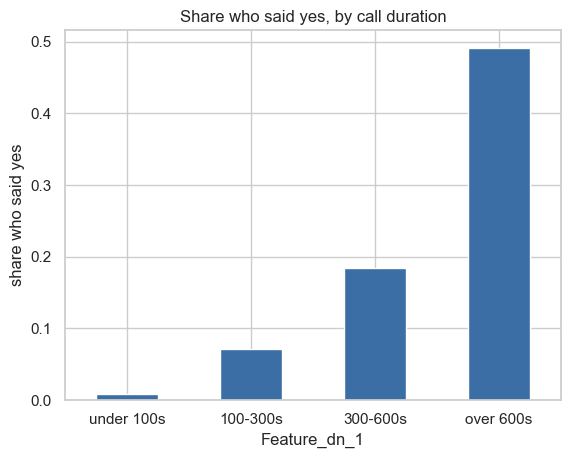

In [32]:
bands = pd.cut(raw.Feature_dn_1, [-1, 100, 300, 600, 5000], labels=['under 100s', '100-300s', '300-600s', 'over 600s'])
raw.groupby(bands).Response.mean().plot.bar(color='#3b6ea5', title='Share who said yes, by call duration')
plt.ylabel('share who said yes'); plt.xticks(rotation=0); plt.show()

**Result:** long calls almost always end in a yes. That looks like a gift, but it is a trap. We only know how long a call lasted **after** it happens, and we need to decide **who to call before** we dial. Using it would be **leakage**: the model would look brilliant on paper and be useless in real life.

---
## Step 3: Fix the problems
**Goal:** clean the data using what we just learned.  **Why:** models learn whatever we feed them, including mistakes.

In [23]:
df = raw.drop_duplicates().reset_index(drop=True)                    # 1. remove the 11 duplicate rows

def prepare(d):
    out = pd.DataFrame(index=d.index)
    out['age']            = d.Feature_ae_0
    out['calls']          = d.Feature_cn_2.clip(upper=10)            # 2. cap extreme call counts at 10
    out['prev_calls']     = d.Feature_ps_4
    out['prev_contacted'] = (d.Feature_ps_3 < 999).astype(int)       # 3. turn the 999 code into a yes/no flag
    for c in ['Feature_ee_5','Feature_cx_6','Feature_cx_7','Feature_em_8','Feature_nd_9']: out[c] = d[c]
    for c in ['Feature_jd_10','Feature_md_11','Feature_ed_12','Feature_dd_13','Feature_hd_14','Feature_ld_15',
              'Feature_cd_16','Feature_md_17','Feature_dd_18','Feature_pd_19']: out[c] = d[c]
    return out                                                       # 4. call duration is left out on purpose

**Result: four fixes**
| Problem | Fix | Why |
|---|---|---|
| 11 duplicate rows | Removed | They would be counted twice |
| 999 in days-since-campaign | Replaced by a yes/no flag "previously contacted" | 999 is a code, not a quantity |
| A few customers called 20-40 times | Capped at 10 | Very few cases, so they would distort the model |
| Call duration | **Excluded** | Leakage: unknown before the call |

---
## Step 4: Split into train and test
**Goal:** hide 30% of the customers in a locked box.  **Why:** to get an honest final score, we must test on customers the model has never seen. All choices from here on use the **training** part only.

In [24]:
train, test = train_test_split(df, test_size=0.30, stratify=df.Response, random_state=SEED)   # 'stratify' keeps the 11% yes-rate in both
X_tr, X_te = prepare(train), prepare(test)
y_tr, y_te = train.Response.values, test.Response.values
print(f'train: {len(train):,} customers | test: {len(test):,} customers | yes-rate: {y_tr.mean():.3f} / {y_te.mean():.3f}')

train: 24,492 customers | test: 10,497 customers | yes-rate: 0.112 / 0.112


---
## Step 5: Which columns actually matter?
**Goal:** find out which columns help separate buyers from non-buyers.  **Why:** columns with no signal only add noise.

We use a score called **Information Value (IV)**. Rough guide: under 0.02 = useless, 0.02-0.1 = weak, 0.1-0.3 = medium, above 0.3 = strong.

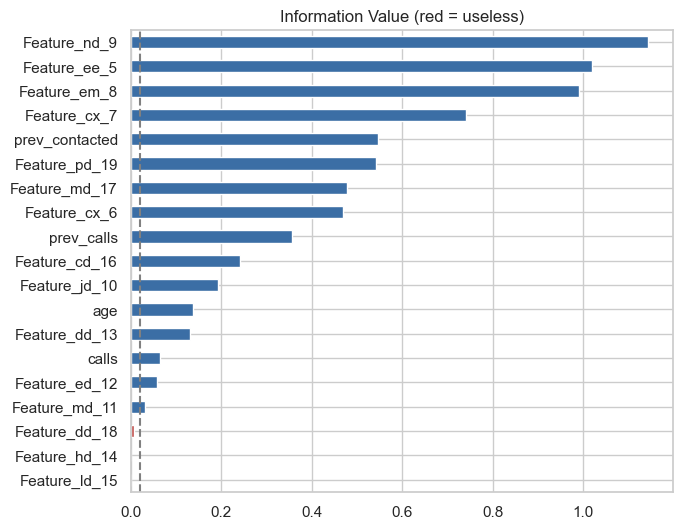

In [25]:
def info_value(x, y):
    t = pd.DataFrame({'x': x, 'y': y}).groupby('x').y.agg(['sum', 'count']); t['no'] = t['count'] - t['sum']; t = t + 0.5
    p_no, p_yes = t['no'] / t['no'].sum(), t['sum'] / t['sum'].sum()
    return float(((p_no - p_yes) * np.log(p_no / p_yes)).sum())

iv = {}
for c in X_tr.columns:
    x = X_tr[c]
    iv[c] = info_value(pd.qcut(x, 10, duplicates='drop') if (pd.api.types.is_numeric_dtype(x) and x.nunique() > 12) else x, y_tr)
iv = pd.Series(iv).sort_values()
iv.plot.barh(figsize=(7, 6), color=['#c0504d' if v < 0.02 else '#3b6ea5' for v in iv]); plt.axvline(0.02, ls='--', c='grey')
plt.title('Information Value (red = useless)'); plt.show()

**Result:**
- **Useless (red):** home loan, personal loan, and weekday of the call. They do not help, so we **drop them**.
- **Strongest:** the economy columns (employment, interest rate, employee numbers), the previous campaign result, and the month.

---
## Step 6: Remove duplicate information
**Goal:** check whether some strong columns are just copies of each other.  **Why:** when columns say the same thing, a simple model like logistic regression cannot tell which one is doing the work, so its results become unstable and hard to explain.

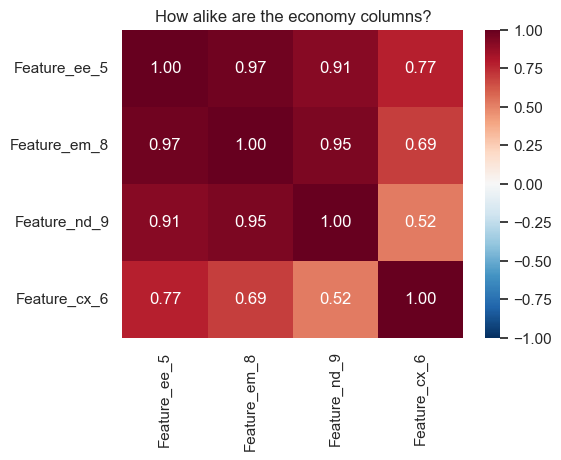

In [26]:
macro = ['Feature_ee_5', 'Feature_em_8', 'Feature_nd_9', 'Feature_cx_6']
plt.figure(figsize=(5.5, 4)); sns.heatmap(X_tr[macro].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1); plt.title('How alike are the economy columns?'); plt.show()

**Result:** `Feature_ee_5` (employment variation), `Feature_em_8` (interest rate) and `Feature_nd_9` (employee numbers) have correlations of **0.91-0.97**. They are nearly the same column three times. We **keep only one**.

Which one? We tested each (details in the full notebook): all three score about the same (differences are smaller than the normal noise), so we picked **`Feature_ee_5`** because it is the easiest to explain: *"is employment going up or down?"*

**Our final list of 14 columns**
- **7 numbers:** age, call attempts, previous-campaign attempts, previously contacted flag, consumer price index, consumer confidence, employment variation
- **7 categories:** employment type, civil status, education, credit default, contact medium, month last contacted, previous campaign outcome

---
## Step 7: Compare three models
**Goal:** see whether a more complicated model beats a simple one.  **Why:** complexity should earn its place.

First, the preparation: categories become 0/1 columns (**one-hot**), tiny categories are grouped together, and numbers are put on the same scale. We test with **5-fold cross-validation**: the training data is cut into 5 slices, and each slice takes a turn as a hidden mini test set.

In [27]:
NUMS = ['age', 'calls', 'prev_calls', 'prev_contacted', 'Feature_cx_6', 'Feature_cx_7', 'Feature_ee_5']
CATS = ['Feature_jd_10', 'Feature_md_11', 'Feature_ed_12', 'Feature_dd_13', 'Feature_cd_16', 'Feature_md_17', 'Feature_pd_19']
COLS = NUMS + CATS
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def make_pipeline(model, scale=True):
    prep = ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', NUMS),
        ('cat', OneHotEncoder(min_frequency=0.01, handle_unknown='infrequent_if_exist', sparse_output=False), CATS)])   # rare categories (<1%) are grouped
    return Pipeline([('prep', prep), ('model', model)])

models = {'Logistic regression (simple)': make_pipeline(LogisticRegression(max_iter=3000)),
          'Random forest':               make_pipeline(RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=0), scale=False),
          'Gradient boosting':           make_pipeline(HistGradientBoostingClassifier(random_state=0), scale=False)}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_tr[COLS], y_tr, cv=cv, scoring='roc_auc')
    rows.append((name, s.mean(), s.std()))
comparison = pd.DataFrame(rows, columns=['model', 'AUC (average)', 'AUC (spread between folds)']).set_index('model')
display(comparison.round(4))

,AUC (average),AUC (spread between folds)
model,,
Logistic regression (simple),0.7835,0.0114
Random forest,0.7822,0.0134
Gradient boosting,0.7828,0.0118


**Result:** all three models score about **0.78**. The complicated ones are **not better**, and the differences (about 0.001) are far smaller than the spread between folds (about 0.01).

**Decision:** we use **logistic regression**, the simple one. When models tie, the simpler one is easier to explain, less likely to memorise noise, and gives trustworthy probabilities, which we need for the money calculation later.

---
## Step 8: Tune the chosen model
**Goal:** find the best setting for logistic regression.  **Why:** it has a "strength of penalty" dial (`C`). Too strong and the model is too rigid; too weak and it can memorise noise.

In [28]:
search = GridSearchCV(make_pipeline(LogisticRegression(solver='liblinear', max_iter=3000)),
                      {'model__penalty': ['l1', 'l2'], 'model__C': [0.01, 0.03, 0.1, 0.3, 1]},
                      cv=cv, scoring='roc_auc').fit(X_tr[COLS], y_tr)
best = search.best_estimator_
print('Best setting:', search.best_params_, '| cross-validated AUC:', round(search.best_score_, 4))

Best setting: {'model__C': 0.1, 'model__penalty': 'l1'} | cross-validated AUC: 0.7847


**Result:** the best setting is a light L1 penalty (`C = 0.1`), with AUC about **0.785**. The scores barely change across settings, so the model is not sensitive to this choice. That is good news.

---
## Step 9: Pick the cut-off (who to call)
**Goal:** decide how high a customer's predicted probability must be before we call them.  **Why:** the usual cut-off of 50% is wrong here. Only 11% buy, so almost nobody reaches 50%.

The right answer depends on money. The Finance team gave us these numbers:

| Outcome | Profit |
|---|---|
| Customer buys: High risk (10% of list) | +285 |
| Customer buys: Medium risk (25%) | +705 |
| Customer buys: Low risk (65%) | +1,225 |
| We call, customer does not buy | -300 |

On average a sale is worth **0.10 × 285 + 0.25 × 705 + 0.65 × 1,225 = 1,001**. We should call someone only if the expected gain is above zero:

> probability × 1,001 − (1 − probability) × 300 > 0  →  **probability > 300 / (1,001 + 300) = 0.2306**

Average sale = 1,001 | wasted call = -300 | cut-off = 0.2306


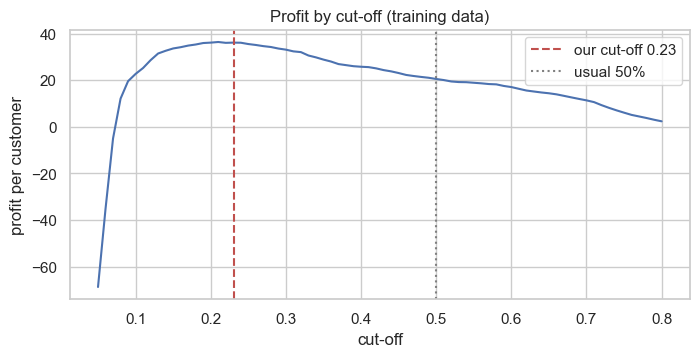

In [29]:
SALE = 0.10*285 + 0.25*705 + 0.65*1225       # average profit of a sale = 1,001
CALL_COST = 300                                # cost of a call that does not convert
CUTOFF = CALL_COST / (SALE + CALL_COST)
print(f'Average sale = {SALE:,.0f} | wasted call = -{CALL_COST} | cut-off = {CUTOFF:.4f}')

# Check on the training data (out-of-fold predictions): does this cut-off really give the best profit?
oof = cross_val_predict(best, X_tr[COLS], y_tr, cv=cv, method='predict_proba')[:, 1]
cuts = np.linspace(0.05, 0.8, 76)
profit = [(((oof >= t) & (y_tr == 1)).sum() * SALE - ((oof >= t) & (y_tr == 0)).sum() * CALL_COST) / len(y_tr) for t in cuts]
plt.figure(figsize=(8, 3.5)); plt.plot(cuts, profit); plt.axvline(CUTOFF, c='#c0504d', ls='--', label=f'our cut-off {CUTOFF:.2f}'); plt.axvline(0.5, c='grey', ls=':', label='usual 50%')
plt.xlabel('cut-off'); plt.ylabel('profit per customer'); plt.title('Profit by cut-off (training data)'); plt.legend(); plt.show()

**Result:** profit is highest around our cut-off of **0.23**, and clearly worse at 50%. The cut-off came from the **money**, not from guesswork.

---
## Step 10: Final check on the test set
**Goal:** score the model on the locked-away 30%.  **Why:** this is the honest score. We look at it **once**, after every decision is made.

Test AUC = 0.802   (cross-validation said 0.785, so no sign of over-fitting)
Precision = 0.46 | Recall = 0.52 | Accuracy = 0.877


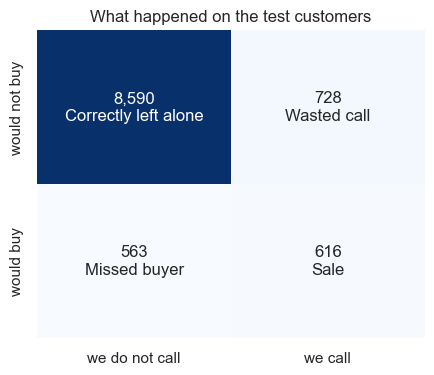

In [30]:
final = best.fit(X_tr[COLS], y_tr)
p_te = final.predict_proba(X_te[COLS])[:, 1]
auc = roc_auc_score(y_te, p_te)
tn, fp, fn, tp = confusion_matrix(y_te, p_te >= CUTOFF).ravel()
print(f'Test AUC = {auc:.3f}   (cross-validation said {search.best_score_:.3f}, so no sign of over-fitting)')
print(f'Precision = {tp/(tp+fp):.2f} | Recall = {tp/(tp+fn):.2f} | Accuracy = {(tp+tn)/len(y_te):.3f}')

fig, ax = plt.subplots(figsize=(5, 4)); n = len(y_te)
sns.heatmap([[tn, fp], [fn, tp]], annot=[[f'{tn:,}\nCorrectly left alone', f'{fp:,}\nWasted call'], [f'{fn:,}\nMissed buyer', f'{tp:,}\nSale']],
            fmt='', cmap='Blues', cbar=False, xticklabels=['we do not call', 'we call'], yticklabels=['would not buy', 'would buy'], ax=ax)
ax.set_title('What happened on the test customers'); plt.show()

**Result:** test AUC is about **0.80**, matching cross-validation, so the model genuinely works on new customers.

**How to read the four boxes**
| Box | Meaning | Share of customers |
|---|---|---|
| Sale (call, buys) | We called, they bought. This pays for the campaign | 5.9% |
| Wasted call (call, no buy) | Cost us 300 each | 6.9% |
| Missed buyer (no call, would buy) | Profit we did not capture (about 1,001 each) | 5.4% |
| Correctly left alone | No cost, no gain | 81.8% |

- **Precision about 0.46:** of the people we call, 46% buy (versus 11% if we called at random: about **4 times better**).
- **Recall about 0.52:** we catch about half of all buyers while calling only about 13% of the list.
- **Accuracy 87.7% is lower than "never call anyone" (88.8%)**, and that is fine: accuracy treats a missed 1,001 sale and a wasted 300 call as the same mistake. They are not. This is why we chose the cut-off with money.

**What matters most?** The model leans mostly on the **economy** (employment variation), then **month**, **contact medium** and **whether the customer was contacted before**. Age, job, civil status and education matter very little. Timing and context beat demographics.

---
## Step 11: Bonus: how much money does the campaign make?
**The question:** the sales team has a list of 10,000 prospects. Assuming our model behaves the same way as on the test set, what is **(a)** the expected profit and **(b)** the profit lost through wrong decisions?

**Assumptions:** we call customers the model flags; we do not call the others (no cost, no profit); every sale earns the average 1,001 (the 10/25/65% risk mix is spread evenly); every call that does not convert costs 300.

In [31]:
N = 10_000
share = {'sale': tp/len(y_te), 'wasted': fp/len(y_te), 'missed': fn/len(y_te), 'left_alone': tn/len(y_te)}
count = {k: v * N for k, v in share.items()}                          # customers in each box on the 10,000 list

# by risk band (the risk mix is assumed the same for every box)
bands = {'High': (0.10, 285), 'Medium': (0.25, 705), 'Low': (0.65, 1225)}
table = pd.DataFrame({b: {'sales': count['sale']*s, 'profit from sales': count['sale']*s*v, 'wasted calls': count['wasted']*s,
                          'cost of wasted calls': -count['wasted']*s*CALL_COST, 'missed buyers': count['missed']*s,
                          'profit missed': count['missed']*s*v} for b, (s, v) in bands.items()}).T
table.loc['Total'] = table.sum()
display(table.round(0).astype(int).map(lambda v: f'{v:,}'))

net_profit  = table.loc['Total', 'profit from sales'] + table.loc['Total', 'cost of wasted calls']
missed      = table.loc['Total', 'profit missed']
wasted      = -table.loc['Total', 'cost of wasted calls']
perfect     = (count['sale'] + count['missed']) * SALE
call_all    = (count['sale'] + count['missed']) * SALE - (count['wasted'] + count['left_alone']) * CALL_COST
print(f'(a) Expected net profit ............ {net_profit:>12,.0f}')
print(f'(b) Profit missed (missed buyers) .. {missed:>12,.0f}')
print(f'    + Money wasted on calls ........ {wasted:>12,.0f}')
print(f'    = Lost to wrong decisions ...... {missed + wasted:>12,.0f}')
print(f'\nFor comparison: call nobody = 0 | call everybody = {call_all:,.0f} | perfect model = {perfect:,.0f}')

,sales,profit from sales,wasted calls,cost of wasted calls,missed buyers,profit missed
High,59,"16,725",69,"-20,806",54,"15,286"
Medium,147,"103,430",173,"-52,015",134,"94,531"
Low,381,"467,267",451,"-135,239",349,"427,064"
Total,587,"587,421",694,"-208,059",536,"536,880"


(a) Expected net profit ............      379,362
(b) Profit missed (missed buyers) ..      536,880
    + Money wasted on calls ........      208,059
    = Lost to wrong decisions ......      744,940

For comparison: call nobody = 0 | call everybody = -1,538,745 | perfect model = 1,124,301


**Answers**
- **(a) Expected net profit: about 379,000.** That is about 587 sales × 1,001 (≈ 587,000) minus about 693 wasted calls × 300 (≈ 208,000).
- **(b) Lost to misclassification: about 745,000.** About 537,000 is profit missed on buyers we did not call, plus about 208,000 spent on calls that did not convert.

*"Lost opportunity" can be read two ways: missed buyers only (≈ 537,000) or missed buyers plus wasted calls (≈ 745,000). Show both and say which one you used.*

**Context:** calling **everyone** would lose about **1.5 million**. A **perfect** model would earn about **1.12 million**. So our model turns a big loss into a profit and captures about a third of what is possible.

---
## Step 12: Summary
**What we built:** a logistic regression that uses 14 columns known **before** a call. Test AUC is about 0.80. Calling only customers with a predicted probability above 23% finds about half of all buyers by calling about 13% of the list.

**The decisions that matter most (and the reason for each)**
| Decision | Reason |
|---|---|
| Left out call duration | Leakage: not known before the call |
| Split the data before choosing anything | Keeps the test score honest |
| Turned 999 into a yes/no flag | 999 is a code, not a number |
| Kept one of three near-identical economy columns | They say the same thing; a simple model cannot separate them |
| Did not resample the data | It would distort the probabilities we need for the money maths |
| Chose the simple model | The complicated ones were no better |
| Cut-off 0.23 from the profit table | The 50% default ignores that a sale (+1,001) is worth more than a wasted call (-300) |
| Did not judge by accuracy | "Never call" already scores 88.8% |

**Things to be honest about**
1. The model leans heavily on the **economic cycle**. If conditions change, performance may drop. Check this before trusting it long-term.
2. A bought prospect list may convert **worse** than our sample. A small pilot would tighten the profit estimate.
3. The profit numbers rest on Finance's table. If sale value or call cost changes, recompute the cut-off with `300 / (sale value + 300)`.

**Want more detail?** The full notebook (`GoTyme_case_study.ipynb`) adds: IV for every column, VIF checks, binning and scaling experiments, over-fitting curves, hyper-parameter searches, calibration, permutation importance, a bootstrap range for the profit, and the precision/recall/profit functions.